# Deuda pública

In [ ]:
# Parámetros de la gráfica
SLUG = "fiscalidad"             # carpeta en research/temas/
GRAFICA_ID = "deuda-publica"    # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Deuda pública"        # `titulo` de la gráfica en config.json
DESDE = 1976                    # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"         # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB"            # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"              # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1               # decimales del CSV (el JSON guarda el valor completo); Eurostat publica un decimal
REFERENCIA = None               # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None               # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** La deuda bruta del conjunto de las administraciones públicas (en España: Estado y resto de la Administración central, comunidades autónomas, entidades locales y Seguridad Social) en porcentaje del PIB, con la definición del procedimiento de déficit excesivo (PDE) de la Unión Europea: efectivo y depósitos, títulos de deuda (letras, bonos y obligaciones) y préstamos, a valor nominal y consolidada, es decir, sin la deuda que unas administraciones tienen con otras. Es la cifra a la que se aplican las reglas fiscales europeas, con un valor de referencia del 60 % del PIB, y el artículo 135 de la Constitución, que remite a ese valor de referencia.

**Cómo se lee.** Es la deuda a 31 de diciembre dividida por el PIB de ese año. Un valor de 100 significa que la deuda equivale a todo lo que produce la economía en un año.

**Limitaciones.**
- Es deuda bruta: no descuenta los activos financieros de las administraciones (depósitos, préstamos concedidos, acciones de empresas públicas).
- No incluye otros pasivos, como las facturas pendientes de pago a proveedores o los compromisos de pensiones con los empleados públicos.
- EE. UU. y Canadá: la OCDE publica para esos países la deuda con esta misma definición, que es la que se usa. La deuda del Economic Outlook de la OCDE usa una definición más amplia y da valores más altos, por lo que no coincide con la de esta gráfica.
- No hay una media de la OCDE con la definición del PDE: la del Economic Outlook incluye más pasivos y no es comparable (la diferencia en España está en la transformación). La serie de la OCDE queda sin dato.
- Las fuentes no publican esta deuda antes de 1995 (la media de la UE-27, antes de 2000).

## 2. Descarga

- **España y UE-27:** Eurostat `gov_10dd_edpt1` (notificación del procedimiento de déficit excesivo): administraciones públicas `S13`, deuda bruta consolidada `GD`, `% del PIB` (`PC_GDP`).
- **EE. UU. y Canadá:** OCDE `OECD.SDD.NAD,DSD_PSD_D1D4@DF_PSD_D1D4` (*Government debt by instrument coverage*), medida `GD` (*Maastricht debt: currency and deposits, debt securities and loans*), administraciones públicas `S13`, `% del PIB` (`PT_B1GQ`). Es trimestral: se toma el cuarto trimestre, la deuda a 31 de diciembre. También se descarga para España, para comprobar que coincide con Eurostat.
- **Solo para comparar definiciones:** OCDE, Economic Outlook (`OECD.ECO.MAD,DSD_EO@DF_EO`, versión 1.5: *Economic Outlook* n.º 119, la misma edición que en las gráficas de gasto, déficit e intereses; se comprueba que sea la última publicada y se quitan los años de proyección con el fichero «Last historical points» de la edición): pasivos financieros brutos de las administraciones públicas `GGFLQ` (la serie que propone el config, la única con media de la OCDE) y deuda Maastricht `GGFLMQ` (solo países europeos).

`lib.oecd.get` solo admite periodos anuales; la serie trimestral se descarga con la misma API y el mismo formato SDMX-CSV en `oecd_cuarto_trimestre`.

In [ ]:
import io
import json
import re
import sys
import xml.etree.ElementTree as ET
from datetime import date
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd
import requests

from lib import estilos, eurostat, oecd
from lib._anual import agregar_anual
from lib._http import pedir
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, write_grafica_data

AREAS_OCDE = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD": "ocde"}
PDE = {"freq": "A", "unit": "PC_GDP", "sector": "S13", "na_item": "GD"}
PSD = "OECD.SDD.NAD,DSD_PSD_D1D4@DF_PSD_D1D4"  # Government debt by instrument coverage (trimestral)
# Economic Outlook: la versión fija la edición (la 1.5 es el n.º 119, la misma que en gasto, déficit e intereses)
EO = "OECD.ECO.MAD,DSD_EO@DF_EO,1.5"


def pedir_oecd(url, etiqueta):
    """GET de metadatos o ficheros de la OCDE, con los reintentos de lib/_http."""
    return pedir(
        requests.Session(), url, None, error_cls=oecd.OecdError, etiqueta=etiqueta,
        mensaje=lambda r: r.text[:200],
    )


def metadatos_eo():
    """Última versión publicada del dataflow y URL del fichero «Last historical points» de la versión usada."""
    agencia, flujo, version = EO.split(",")
    base = oecd.BASE.removesuffix("/data") + f"/dataflow/{agencia}/{flujo}"
    ns = {"s": "http://www.sdmx.org/resources/sdmxml/schemas/v2_1/structure"}
    ultima = ET.fromstring(pedir_oecd(f"{base}/latest", "versión").content).find(".//s:Dataflow", ns).get("version")
    texto = pedir_oecd(f"{base}/{version}", "metadatos").text
    urls = sorted(set(re.findall(r"https://[^\s\"'<>&]+Last_Historical[^\s\"'<>&]+\.xlsx", texto)))
    if len(urls) != 1:
        raise oecd.OecdError(f"se esperaba un enlace al fichero de últimos datos observados y hay {len(urls)}")
    return ultima, urls[0]


def ultimos_observados(url, variables):
    """Último año observado (no proyectado) de cada variable por serie de la cesta, según «Last historical points»."""
    bruto = pd.read_excel(io.BytesIO(pedir_oecd(url, "últimos datos observados").content), header=None)
    fila = next(i for i, v in bruto.iloc[:, 0].items() if v == "Country Code")
    tabla = bruto.iloc[fila + 1:].set_axis(bruto.iloc[fila].tolist(), axis=1)
    return {
        v: {
            AREAS_OCDE[c]: int(a)
            for c, a in zip(t["Country Code"], t["Last Observation annual"]) if c in AREAS_OCDE and pd.notna(a)
        }
        for v, t in ((v, tabla[tabla["Variable code"] == v]) for v in variables)
    }


def oecd_cuarto_trimestre(dataflow, clave, areas):
    """Serie trimestral de saldos de la OCDE → anual, con el cuarto trimestre (saldo a 31 de diciembre).

    Misma API y mismo formato que `oecd.get`. Un año sin cuarto trimestre (el año en curso) queda fuera.
    """
    etiqueta = dataflow.split(",")[1]
    r = pedir(
        requests.Session(), f"{oecd.BASE}/{dataflow}/{clave.replace('{AREA}', '+'.join(areas))}",
        {"startPeriod": f"{DESDE}-Q1"}, error_cls=oecd.OecdError, etiqueta=etiqueta,
        mensaje=lambda r: r.text[:200], headers=oecd.CABECERA_CSV,
    )
    raw = pd.read_csv(io.StringIO(r.text), dtype=str)
    raw = raw[raw["REF_AREA"].isin(areas) & raw["TIME_PERIOD"].str.fullmatch(r"\d{4}-Q4")]
    obs = pd.DataFrame({
        "serie": raw["REF_AREA"].map(areas),
        "anio": raw["TIME_PERIOD"].str[:4].astype(int),
        "orden": raw["TIME_PERIOD"],
        "valor": pd.to_numeric(raw["OBS_VALUE"]),
    })
    return agregar_anual(obs, None, f"{etiqueta}: ")  # sin agregación: error si hay más de un dato por año


def descargar():
    pde, f_pde = eurostat.get("gov_10dd_edpt1", PDE, desde=DESDE)
    psd = oecd_cuarto_trimestre(PSD, "Q.{AREA}.GD.PT_B1GQ.S13", AREAS_OCDE)
    eo_ggfl, _ = oecd.get(EO, "{AREA}.GGFLQ.A", areas=AREAS_OCDE, desde=DESDE)
    eo_maas, _ = oecd.get(EO, "{AREA}.GGFLMQ.A", areas=AREAS_OCDE, desde=DESDE)
    return pde, f_pde, psd, eo_ggfl, eo_maas


pde, f_pde, psd, eo_ggfl, eo_maas = descargar()

# Economic Outlook sin proyecciones: cada país hasta su último año observado según «Last historical points». El
# fichero no da fecha para los agregados, así que la media de la OCDE (que solo se usa para comprobar que existe
# con esta definición) queda fuera de las tablas.
version_ultima, url_lho = metadatos_eo()
EDICION = re.search(r"EO_?(\d+)\.xlsx$", url_lho).group(1)
assert "ocde" in set(eo_ggfl["serie"]), "El Economic Outlook ya no publica GGFLQ para la media de la OCDE: revisa la nota"
ultimo_eo = ultimos_observados(url_lho, ["GGFLQ", "GGFLMQ"])
eo_ggfl = eo_ggfl[eo_ggfl["periodo"] <= eo_ggfl["serie"].map(ultimo_eo["GGFLQ"])]
eo_maas = eo_maas[eo_maas["periodo"] <= eo_maas["serie"].map(ultimo_eo["GGFLMQ"])]
version = EO.rsplit(",", 1)[1]
if version_ultima != version:
    print(f"AVISO: la OCDE publica la versión {version_ultima} del dataflow y aquí se usa la {version}: actualiza EO.")
print(f"Economic Outlook {EDICION} (dataflow versión {version})")
for nombre, d in [("Eurostat gov_10dd_edpt1 (GD)", pde), ("OCDE DSD_PSD_D1D4 (GD)", psd),
                  ("OCDE EO (GGFLQ)", eo_ggfl), ("OCDE EO (GGFLMQ)", eo_maas)]:
    cobertura = d.dropna().groupby("serie")["periodo"].agg(["min", "max"])
    print(nombre, "·", "; ".join(f"{s}: {a}-{b}" for s, (a, b) in cobertura.iterrows()))

Economic Outlook 119 (dataflow versión 1.5)
Eurostat gov_10dd_edpt1 (GD) · espana: 1995-2025; ue27: 2000-2025
OCDE DSD_PSD_D1D4 (GD) · canada: 1995-2025; eeuu: 1995-2025; espana: 1995-2025
OCDE EO (GGFLQ) · canada: 1976-2025; eeuu: 1976-2025; espana: 1980-2025
OCDE EO (GGFLMQ) · espana: 1995-2025


## 3. Transformación

**¿Qué series de la OCDE miden lo mismo que la deuda PDE?** Se comprueba en España, la única área que está en todas las fuentes. **Criterio:** una serie de la OCDE se considera comparable si en ningún año común difiere de la deuda PDE de Eurostat en más de `UMBRAL` = 0,5 puntos del PIB (margen para redondeos y revisiones). Solo se miran los años con dato de Eurostat, lo que deja fuera las proyecciones del Economic Outlook.

- La deuda Maastricht de `DSD_PSD_D1D4` coincide con Eurostat: se usa para EE. UU. y Canadá.
- `GGFLMQ` del Economic Outlook también coincide, pero la OCDE solo la publica para países europeos: sirve solo de contraste.
- `GGFLQ` (pasivos financieros brutos) no es comparable: añade otros pasivos, como las cuentas pendientes de pago, y valora los títulos de deuda a precio de mercado. Es la única con media de la OCDE, que por eso queda sin dato.

Las comprobaciones (`assert`) paran el notebook si una nueva edición de los datos cambia alguna de estas conclusiones, para revisar las notas.

In [ ]:
def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    hoy = date.today().isoformat()
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, hoy) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


def de(d, serie):
    return d[d["serie"] == serie].set_index("periodo")["valor"].dropna()


fmt = estilos.formato_es
UMBRAL = 0.5  # puntos del PIB

# 1. Comparación de definiciones en España (años con dato de Eurostat)
GD_OCDE, GGFLMQ, GGFLQ = "OCDE GD (DSD_PSD_D1D4)", "OCDE EO GGFLMQ", "OCDE EO GGFLQ"
pde_es = de(pde, "espana")
tabla = pd.DataFrame({
    "Eurostat GD": pde_es,
    GD_OCDE: de(psd, "espana"),
    GGFLMQ: de(eo_maas, "espana"),
    GGFLQ: de(eo_ggfl, "espana"),
}).loc[pde_es.index]
dif = tabla.drop(columns="Eurostat GD").sub(pde_es, axis=0)
resumen = pd.DataFrame({
    "años comunes": dif.notna().sum(),
    "dif. mínima": dif.min(),
    "dif. máxima": dif.max(),
    "máx. absoluta": dif.abs().max(),
})
resumen["comparable"] = resumen["máx. absoluta"] <= UMBRAL
print("España, % del PIB (diferencias: serie de la OCDE menos Eurostat GD)")
print(tabla.join(dif.add_prefix("dif. ")).round(1).to_string())
print()
print(resumen.round(2).to_string())

assert resumen.loc[GD_OCDE, "comparable"], "La deuda Maastricht de la OCDE ya no coincide con Eurostat: revisa EE. UU. y Canadá"
assert resumen.loc[GD_OCDE, "años comunes"] == len(pde_es), "La OCDE no cubre todos los años de Eurostat: revisa la nota"
assert not resumen.loc[GGFLQ, "comparable"], "GGFLQ ya coincide con la deuda PDE: revisa la serie de la OCDE"
assert resumen.loc[GGFLQ, "dif. mínima"] > 0, "GGFLQ ya no supera siempre a la deuda PDE: revisa la nota de la OCDE"
assert set(eo_maas["serie"]) == {"espana"}, "El Economic Outlook publica GGFLMQ para otras áreas de la cesta: revísalo"
assert "ocde" not in set(psd["serie"]), "La OCDE publica la deuda Maastricht de su media: úsala"

# 2. Series de la gráfica: Eurostat (España, UE-27) y deuda Maastricht de la OCDE (EE. UU., Canadá)
df = pd.concat([pde, psd[psd["serie"].isin(["eeuu", "canada"])]], ignore_index=True)
hoy = date.today().isoformat()
fuentes = [FuenteMeta(f.serie, f.organismo, "gov_10dd_edpt1 (S13, GD, PC_GDP)", f.url, f.fecha_consulta) for f in f_pde]
fuentes += [
    FuenteMeta(s, oecd.ORGANISMO, f"{PSD} (GD, S13, PT_B1GQ; cuarto trimestre)", oecd.URL_EXPLORER, hoy)
    for s in ("eeuu", "canada")
]
OCDE = (oecd.ORGANISMO, f"{EO} (GGFLQ, consultada, no comparable); {PSD} (GD, sin media de la OCDE)", oecd.URL_EXPLORER)
df, fuentes = anadir_sin_dato(df, fuentes, {"ocde": OCDE})

# 3. Cifras para las notas
primeros = df.dropna().groupby("serie")["periodo"].min()
assert primeros["espana"] == primeros["eeuu"] == primeros["canada"] <= primeros["ue27"], "Revisa la nota de años sin dato"
d_ggfl = dif[GGFLQ].dropna()
amplia = {}  # EE. UU. y Canadá: GGFLQ menos GD en el último año con las dos (años con dato de GD, sin proyecciones)
for s in ("eeuu", "canada"):
    gd, gg = de(psd, s), de(eo_ggfl, s)
    a = gd.index.intersection(gg.index).max()
    amplia[s] = (a, gg[a] - gd[a])
assert amplia["eeuu"][0] == amplia["canada"][0] and min(v for _, v in amplia.values()) > 0
print()
print("GGFLQ menos GD:", {s: (a, round(v, 1)) for s, (a, v) in amplia.items()})

NOTAS = [
    "España y UE-27: Eurostat gov_10dd_edpt1, deuda bruta consolidada de las administraciones públicas según el procedimiento de déficit excesivo (sector S13, GD): efectivo y depósitos, títulos de deuda y préstamos, a valor nominal. UE-27 de composición actual (EU27_2020).",
    f"Los años anteriores a {primeros['espana']} quedan sin dato porque las fuentes no los publican: Eurostat publica la deuda PDE con la metodología SEC 2010 desde {primeros['espana']}, y su agregado de la UE-27 desde {primeros['ue27']}; la serie de la OCDE para EE. UU. y Canadá también empieza en {primeros['espana']}.",
    "EE. UU. y Canadá: OCDE, deuda pública por cobertura de instrumentos (DSD_PSD_D1D4), medida «deuda Maastricht» (GD) de las administraciones públicas: efectivo y depósitos, títulos de deuda a valor nominal y préstamos, la misma definición. La serie es trimestral y se toma el cuarto trimestre, la deuda a 31 de diciembre.",
    f"En España, la deuda Maastricht de la OCDE coincide con la de Eurostat en todos los años ({tabla[GD_OCDE].notna().sum()} años, diferencia máxima de {fmt(resumen.loc[GD_OCDE, 'máx. absoluta'], 2)} puntos del PIB).",
    f"OCDE: la media de la OCDE solo se publica en el Economic Outlook (n.º {EDICION}) con la definición de pasivos financieros brutos (GGFLQ), que añade otros pasivos, como las cuentas pendientes de pago, y valora los títulos de deuda a precio de mercado; en España supera a la deuda PDE entre {fmt(d_ggfl.min(), 1)} y {fmt(d_ggfl.max(), 1)} puntos del PIB en {d_ggfl.index.min()}-{d_ggfl.index.max()}, así que no es comparable y la serie queda sin dato.",
    f"Con esa definición amplia, la OCDE da en {amplia['eeuu'][0]} una deuda mayor que la de esta gráfica también en EE. UU. ({fmt(amplia['eeuu'][1], 1)} puntos del PIB más) y en Canadá ({fmt(amplia['canada'][1], 1)} puntos más).",
]

# Series que acaban antes que las demás (p. ej. si una fuente aún no ha publicado el último año)
NOMBRES = {b["id"]: b["nombre"] for b in json.loads((RAIZ / "global.json").read_text(encoding="utf-8"))["benchmarks"]}
ultimos = df.dropna().groupby("serie")["periodo"].max()
NOTAS += [f"{NOMBRES[s]}: último dato disponible en {a}." for s, a in ultimos.items() if a < ultimos.max()]

España, % del PIB (diferencias: serie de la OCDE menos Eurostat GD)
         Eurostat GD  OCDE GD (DSD_PSD_D1D4)  OCDE EO GGFLMQ  OCDE EO GGFLQ  dif. OCDE GD (DSD_PSD_D1D4)  dif. OCDE EO GGFLMQ  dif. OCDE EO GGFLQ
periodo                                                                                                                                          
1995            61.6                    61.6            61.6           68.3                         -0.0                 -0.0                 6.7
1996            65.4                    65.4            65.4           74.7                          0.0                  0.0                 9.3
1997            64.3                    64.3            64.3           73.7                         -0.0                 -0.0                 9.4
1998            62.4                    62.4            62.4           73.7                         -0.0                 -0.0                11.3
1999            60.9                    60.9            

## 4. Visualización

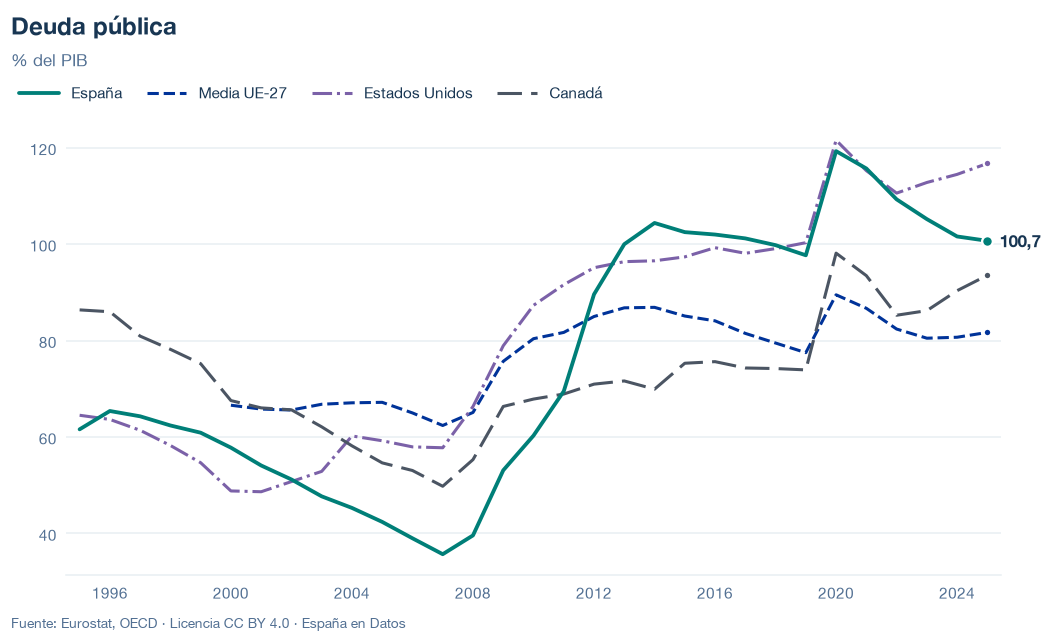

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/deuda-publica.json y data/deuda-publica.csv


## 6. Fuentes, notas y licencia

**Fuentes:**
- Eurostat, `gov_10dd_edpt1` (España y UE-27).
- OCDE, `DSD_PSD_D1D4@DF_PSD_D1D4`, medida `GD` (EE. UU. y Canadá; para España, solo como comprobación).
- OCDE, Economic Outlook `DSD_EO@DF_EO` (versión 1.5, edición n.º 119), medidas `GGFLQ` y `GGFLMQ` y fichero «Last historical points» de la edición, solo para comparar definiciones (consultada para la media de la OCDE, sin dato comparable).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Notas:** en `NOTAS` (definición, composición de la UE-27, años sin dato y comparación entre definiciones); `writer.py` añade el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.